In [1]:
import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
import os
import bokeh.plotting as bok
import pandas as pd
import ast

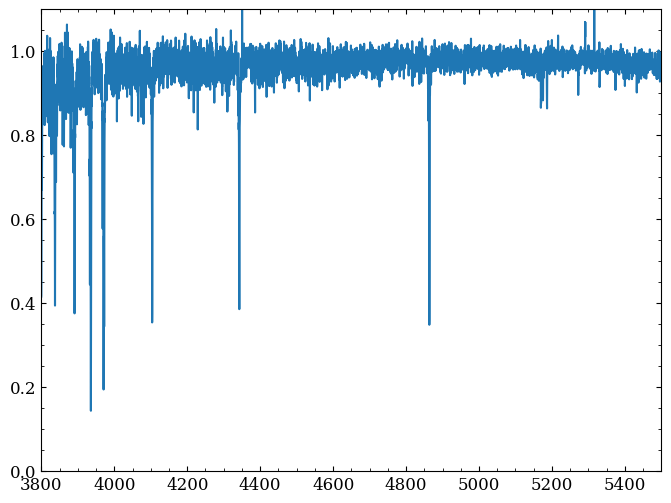

In [15]:
data = pd.read_csv('/data/misfit/benlowe/xshooter/reduced_data/norm_spec/all/ra_1633-2814_s284/uvb/ra_1633-2814_s284_uvb_ob1.csv')

plt.figure(figsize=[8,6])
plt.plot(data['wave'], data['normed_flux'])
plt.xlim(3800, 5500)
plt.ylim(0, 1.1)
# plt.xlabel(r'Wavelength ($\AA$)')
# plt.ylabel('Normalised Flux')
# plt.tight_layout()

plt.savefig('/data/misfit/benlowe/feb25/norm_spec.png', dpi=300, transparent=False, facecolor='white')

Picking one of our stars, and plotting where the absorption lines are located

In [3]:
# Loading in linelist
linelist = pd.read_csv('/data/misfit/benlowe/lines.csv')
linelist = linelist.sort_values(by='wave')
display(linelist)

line_waves = linelist['wave'].to_numpy()


,species,wave,elow,loggf,ew
835,Fe1,3000.451,1.49,-1.095,93.766
2065,Co1,3000.548,0.10,-2.120,34.306
105,Ca1,3000.863,1.89,-0.862,22.764
212,Ti1,3000.865,0.05,-0.830,40.373
663,Cr1,3000.884,1.00,-0.150,63.922
...,...,...,...,...,...
57,Mg1,38657.637,6.78,0.803,25.167
58,Mg1,42001.188,6.43,0.474,28.063
59,Mg1,42001.820,6.43,0.470,27.826
102,Si1,54586.602,5.96,-0.078,26.342


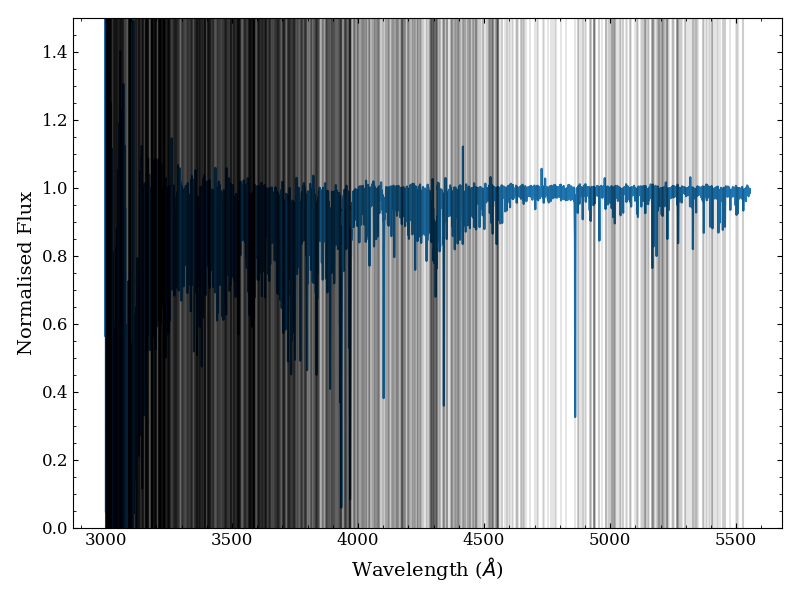

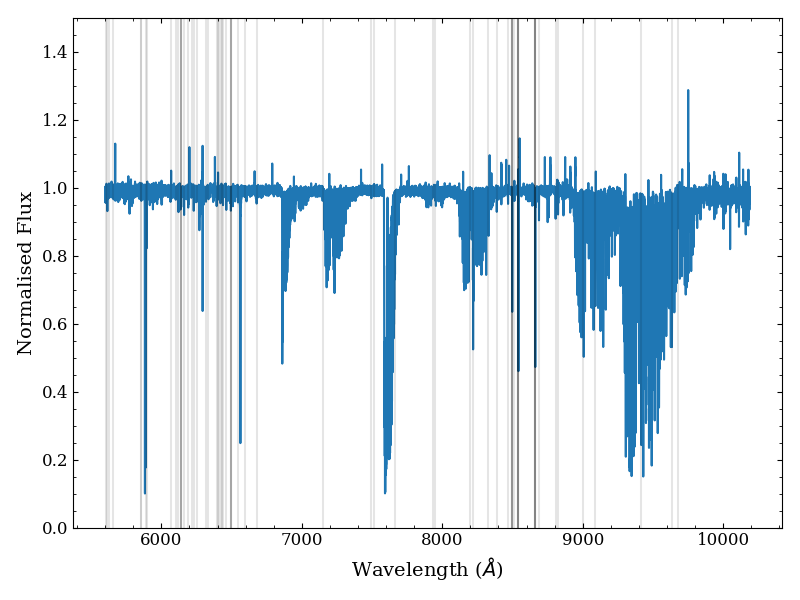

In [18]:
# Loading in the data
fits_path = '/data/misfit/benlowe/xshooter/reduced_data/comb_spec/ra_1752-4300_s6/ra_1752-4300_s6_data.fits'
fits_info = fits.open(fits_path)
uvb_data = fits_info[1].data
vis_data = fits_info[2].data

uvb_wave = uvb_data['wave']
uvb_flux = uvb_data['flux']
vis_wave = vis_data['wave']
vis_flux = vis_data['flux']

# Splitting the linelist into UVB and VIS
uvb_lines = linelist[(linelist['wave'] > min(uvb_wave)) & (linelist['wave'] < max(uvb_wave))] # & (linelist['loggf'] > -3.0)
vis_lines = linelist[(linelist['wave'] > min(vis_wave)) & (linelist['wave'] < max(vis_wave))] # & (linelist['loggf'] > -3.0)

# %matplotlib widget
plt.figure(figsize=[8,6])
plt.plot(uvb_wave, uvb_flux, label='UVB')
for i, line in uvb_lines.iterrows():
    plt.axvline(line['wave'], color='k', alpha=0.1)
plt.xlabel(r'Wavelength ($\AA$)')
plt.ylabel('Normalised Flux')
plt.ylim(top=1.5, bottom=0)
plt.tight_layout()
# plt.savefig('uvb_lines.png', dpi=300, transparent=False, facecolor='white')

plt.figure(figsize=[8,6])
plt.plot(vis_wave, vis_flux, label='VIS')
for i, line in vis_lines.iterrows():
    plt.axvline(line['wave'], color='k', alpha=0.1)
plt.xlabel(r'Wavelength ($\AA$)')
plt.ylabel('Normalised Flux')
plt.ylim(top=1.5, bottom=0)
plt.tight_layout()
# plt.savefig('vis_lines.png', dpi=300, transparent=False, facecolor='white')

Loading in test sample spectra to help isolate what to do and what not tio do

In [16]:
uvb_test_df

,ob,star_id,snr,wave,flux,flux_err,flux_weight,wave_norm,flux_norm,flux_err_norm,flux_weight_norm,shift,spec_shift,spec_err_shift
0,OB1,ra_1648-0653_s38,81.503061,[2989.2 2989.4 2989.6 ... 5559.4 5559.6 5559.8],[-1137.41137695 -1893.5032959 -1195.2791748 ...,[677.06964111 654.54095459 686.62451172 ... 30...,[2.18139000e-06 2.33413703e-06 2.12110122e-06 ...,[3000. 3000.2 3000.4 ... 5559.4 5559.6 5559.8],[-0.62886089 -1.26644941 -0.09888513 ... 0.96...,[9360.62626518 9099.63544223 9527.60854308 ......,[1.14127470e-08 1.20768039e-08 1.10162096e-08 ...,0,[-0.62886089 -1.26644941 -0.09888513 ... 0.96...,[9360.62626518 9099.63544223 9527.60854308 ......
1,OB2,ra_1648-0653_s38,70.378847,[2989.2 2989.4 2989.6 ... 5559.4 5559.6 5559.8],[-5999.59277344 -2590.45776367 -5960.82861328 ...,[707.08703613 705.09710693 685.30883789 ... 27...,[2.00011170e-06 2.01141708e-06 2.12925333e-06 ...,[3000. 3000.2 3000.4 ... 5559.4 5559.6 5559.8],[-2.17866512 -3.43772434 -2.92620848 ... 0.99...,[6611.42546361 6410.86745526 6431.77013644 ......,[2.28775645e-08 2.43313611e-08 2.41734686e-08 ...,0,[-2.17866512 -3.43772434 -2.92620848 ... 0.99...,[6611.42546361 6410.86745526 6431.77013644 ......
2,OB3,ra_1648-0653_s38,66.610865,[2989.2 2989.4 2989.6 ... 5559.4 5559.6 5559.8],[-3504.50292969 -5401.93701172 -5081.19287109 ...,[774.80535889 707.97235107 733.371521 ... 26...,[1.66576897e-06 1.99511257e-06 1.85931048e-06 ...,[3000. 3000.2 3000.4 ... 5559.4 5559.6 5559.8],[-2.0812687 -2.67272463 -4.47220888 ... 0.96...,[5185.48500213 5218.71572206 5642.59477949 ......,[3.71895767e-08 3.67174675e-08 3.14081441e-08 ...,0,[-2.0812687 -2.67272463 -4.47220888 ... 0.96...,[5185.48500213 5218.71572206 5642.59477949 ......


In [27]:
uvb_test_df[uvb_test_df['ob'] == 'OB1']['wave_norm'].apply(ast.literal_eval)

SyntaxError: invalid syntax (<unknown>, line 1)

ValueError: could not convert string to float: '['

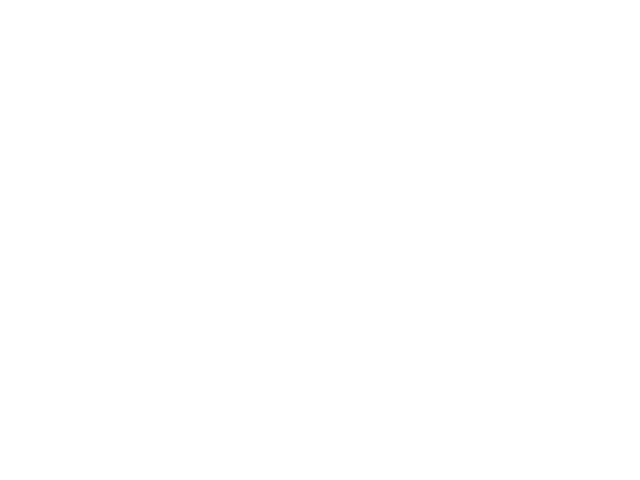

In [41]:
# Loading in the test data
uvb_test_df = pd.read_csv('/data/misfit/benlowe/xshooter/reduced_data/comb_spec/test_shifted_uvb.csv')
vis_test_df = pd.read_csv('/data/misfit/benlowe/xshooter/reduced_data/comb_spec/test_shifted_vis.csv')

# Plotting them all together
%matplotlib widget
plt.figure()
for i, uvb_exp in uvb_test_df.iterrows():
    wave = uvb_exp['wave_norm']
    flux = [float(j) for j in uvb_exp['spec_shift']]
    print(flux)
    
    
    # plt.plot(wave, flux)


Create a rolling window to remove cosmic rays

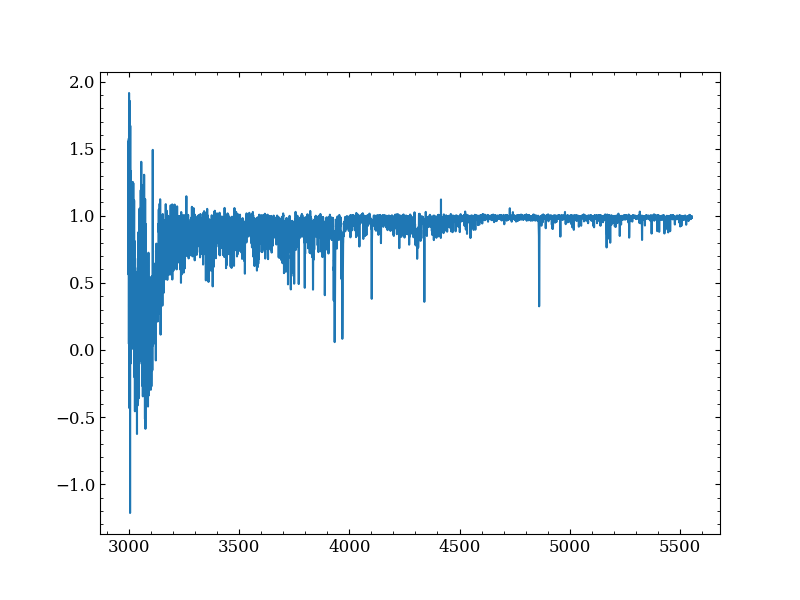

In [5]:
# Converting to series 
uvb_flux_series = pd.Series(uvb_flux)
uvb_wave_series = pd.Series(uvb_wave)
window_size = 500

# Getting rolling windows
winds_flux = [window.values for window in uvb_flux_series.rolling(window=window_size, center=True)]
winds_wave = [window.values for window in uvb_wave_series.rolling(window=window_size, center=True)]

plt.figure(figsize=[8,6])
plt.plot(uvb_wave, uvb_flux)